# Saved pilot results and cost planning

Stage 2 is **incomplete**: eleven one-case reasoning pilots passed artifact checks; Consulting stopped on HTTP 503 without usage. Paid work is blocked pending charge reconciliation. Beer, EDT, Retail, ICBE and genuine Kaggle pilots have not run.

Run All reads committed, sanitized artifacts only. It does not create clients, read credentials or call an API. These are diagnostic pilots, not full native evaluations or evidence that LLMs adapt to business shocks. The Factset case is a local extension.

In [1]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
artifacts = ROOT / 'docs/results/stage2'
report = json.loads((artifacts / 'pilot_cost_report.json').read_text())
budget = json.loads((artifacts / 'budget_summary.json').read_text())
reconciliation = json.loads((artifacts / 'billing_reconciliation.json').read_text())
events = [json.loads(line) for line in (artifacts / 'native_pilot_attempts.jsonl').read_text().splitlines()]
starts = [e for e in events if e['event'] == 'started']
finished = [e for e in events if e['event'] == 'finished']
assert len(starts) == len(finished) == report['totals']['attempts'] == budget['attempts']
assert sum(e.get('cost_usd') is None for e in finished) == report['totals']['missing_usage_attempts']
assert abs(sum(e.get('cost_usd') or 0 for e in finished) - budget['known_cost_usd']) < 1e-9
assert budget['uncertain_attempts'] == 1 and not reconciliation['paid_calls_may_resume']
report['totals']

{'attempts': 22,
 'known_estimated_cost_usd': 0.01899748,
 'missing_usage_attempts': 1,
 'validated_native_pilot_tasks': 11,
 'known_projection_subtotal_base_usd': 0.444966615,
 'unmeasured_tasks': ['retail:dynamic_middle',
  'retail:dynamic_hard',
  'retail:still_middle',
  'retail:still_hard',
  'firm:consulting',
  'firm:beergame',
  'firm:edt',
  'icbe',
  'kaggle:primary_matrix'],
 'full_suite_cost_estimate_usd': None,
 'budget_decision': 'No large-run cap recommended until missing pilots and charging reconciliation are complete.',
 'qualification': 'Gateway-credit tariff estimates, not independently verified billing. Subtotal excludes missing families; it is not a full-suite budget.'}

## Native pilot outcomes

A valid but incorrect answer is a completed scoring observation. It is not discarded, repaired to match the reference or repeated to improve the score. One case per dataset gives no reliable dataset-level accuracy estimate. Consulting has no final score because the interview and judge workflow did not finish.

In [2]:
usage = pd.DataFrame(report['observations'])
usage['correct'] = usage['native_score'].map(lambda score: score.get('correct') if isinstance(score, dict) else None)
usage[['task', 'validation_status', 'attempts', 'correct', 'input_tokens', 'output_tokens', 'missing_usage_attempts', 'known_estimated_cost_usd']]

,task,validation_status,attempts,correct,input_tokens,output_tokens,missing_usage_attempts,known_estimated_cost_usd
0,firm:CodeFinQA,validated_complete,1,0.0,925,144,0,0.000962
1,firm:CodeTAT-QA,validated_complete,1,1.0,825,163,0,0.000946
2,firm:consulting,requires_review,11,NaN,22692,1643,1,0.009682
3,firm:ConvFinQA,validated_complete,1,1.0,867,86,0,0.000776
4,firm:factset,validated_complete,1,0.0,431,226,0,0.000855
5,firm:FinCode,validated_complete,1,1.0,380,94,0,0.000484
6,firm:finer,validated_complete,1,1.0,1792,279,0,0.001863
7,firm:FinKnow,validated_complete,1,1.0,217,280,0,0.000857
8,firm:formula,validated_complete,1,0.0,175,101,0,0.000371
9,firm:FormulaEval,validated_complete,1,1.0,367,98,0,0.000486


In [3]:
rows = []
for e in finished:
    u = e.get('usage') or {}
    rows.append({'model': e['requested_model'], 'status': e['status'],
                 'latency_seconds': e['latency_seconds'], 'input_tokens': u.get('prompt_tokens'),
                 'output_tokens': u.get('completion_tokens'), 'cost': e.get('cost_usd')})
model_usage = pd.DataFrame(rows)
model_usage.groupby('model').agg(attempts=('status', 'size'), known_cost=('cost', 'sum'),
    input_tokens=('input_tokens', 'sum'), output_tokens=('output_tokens', 'sum'),
    latency_median_seconds=('latency_seconds', 'median'), latency_p95_seconds=('latency_seconds', lambda s: s.quantile(.95)))

,attempts,known_cost,input_tokens,output_tokens,latency_median_seconds,latency_p95_seconds
model,,,,,,
gpt-4.1-mini-2025-04-14,16,0.015454,12721.0,2849.0,12.936653,14.969364
gpt-4o-mini-2024-07-18,6,0.003543,17689.0,499.0,2.906838,11.336195


## Spending and the stop condition

The ledger retains an unresolved reservation; it never treats missing usage as zero. Provider history uniquely matches the 21 completed responses by model, tokens and time, totaling $0.017866 reported gateway credit. Their local uncached tariff upper estimate is $0.01899748. Provider account-history totals also include earlier calls and are not the pilot total. The HTTP 503 charge remains unresolved; the rounded $19.98 balance does not settle it.

Limits depend on the published tariff and gateway honoring token ceilings. They are not a provider-enforced dollar quota, independently audited billing, or the cash price of credit.

In [4]:
pd.DataFrame([budget]).T

,0
budget_id,stage2_pilot_v1
currency,USD_gateway_credit
attempts,22
known_cost_usd,0.018997
unresolved_reserved_usd,0.007691
exposure_usd,0.026688
pending_attempts,0
uncertain_attempts,1
cap_usd,1.0
allowance_sha256,8ab6a7a2da3bf1485f55c66a17a804a6a7ab8fa5e3678d...


## Partial cost and time projections

For each reasoning dataset, multiply its one-case observed usage and latency by the frozen case count. Low/base/high use explicit **0.75? / 1? / 2? planning assumptions**, not confidence intervals or observed bounds. Missing families stay missing. Retail context growth, tool calls, judge calls, failed requests and retries can dominate the unmeasured total. Serial API time excludes local processing and queue overhead; concurrency changes elapsed time.

In [5]:
projection = pd.DataFrame(report['projections'])
projection[['task', 'projection_status', 'full_units', 'full_horizon', 'cost_low_scenario_usd', 'cost_base_scenario_usd', 'cost_high_scenario_usd', 'serialized_api_seconds_base']]

,task,projection_status,full_units,full_horizon,cost_low_scenario_usd,cost_base_scenario_usd,cost_high_scenario_usd,serialized_api_seconds_base
0,retail:dynamic_middle,not_estimable_yet,1.0,180.0,NaN,NaN,NaN,NaN
1,retail:dynamic_hard,not_estimable_yet,1.0,180.0,NaN,NaN,NaN,NaN
2,retail:still_middle,not_estimable_yet,1.0,180.0,NaN,NaN,NaN,NaN
3,retail:still_hard,not_estimable_yet,1.0,180.0,NaN,NaN,NaN,NaN
4,firm:FinCode,linear_single_pilot_scenario,7.0,NaN,0.002543,0.003391,0.006782,95.600207
5,firm:CodeFinQA,linear_single_pilot_scenario,50.0,NaN,0.036069,0.048092,0.096184,161.869915
6,firm:CodeTAT-QA,linear_single_pilot_scenario,50.0,NaN,0.035492,0.047323,0.094646,666.968350
7,firm:SEC-NUM,linear_single_pilot_scenario,50.0,NaN,0.034627,0.046170,0.092339,71.876910
8,firm:TAT-QA,linear_single_pilot_scenario,50.0,NaN,0.029653,0.039537,0.079075,744.478030
9,firm:ConvFinQA,linear_single_pilot_scenario,50.0,NaN,0.029100,0.038800,0.077601,130.562350


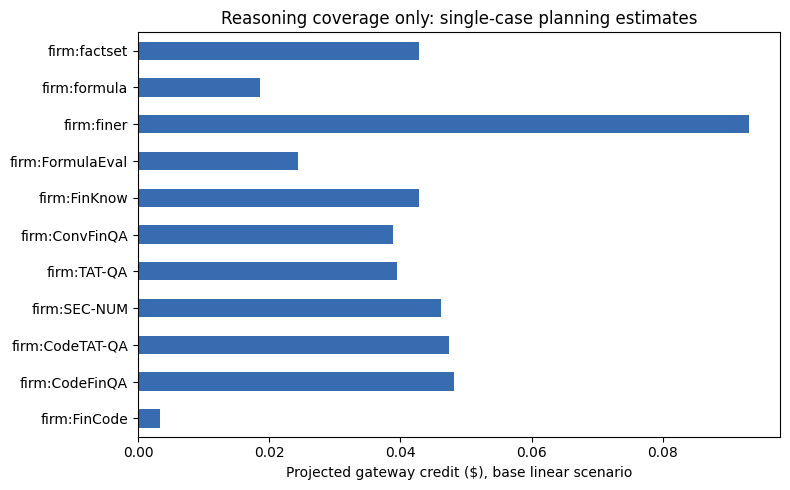

Reasoning-only base subtotal: 0.444967
Reasoning-only serial API minutes: 90.1
Full-suite estimate: None


In [6]:
measured = projection.dropna(subset=['cost_base_scenario_usd'])
ax = measured.set_index('task')['cost_base_scenario_usd'].plot.barh(figsize=(8, 5), color='#386cb0')
ax.set(xlabel='Projected gateway credit ($), base linear scenario', ylabel='', title='Reasoning coverage only: single-case planning estimates')
plt.tight_layout()
plt.show()
print('Reasoning-only base subtotal:', round(measured['cost_base_scenario_usd'].sum(), 6))
print('Reasoning-only serial API minutes:', round(measured['serialized_api_seconds_base'].sum() / 60, 1))
print('Full-suite estimate:', report['totals']['full_suite_cost_estimate_usd'])

## Reproduce and inspect

From the project root, regenerate local summaries with `python scripts/summarize_pilot_costs.py`. Validate an individual saved run with `python scripts/validate_benchmark_run.py results/benchmarks/<task>/<run_id>`. Local raw requests/responses remain under each ignored run folder. The committed first CodeFinQA response, native score, validations and attempt metadata support review without another paid call.

Next: reconcile failed attempt `78b37b3af16842ad81504f03fa222ae9`, resume bounded pilots under the existing allowance, then finish a measured full-scope budget decision. Do not start Stage 3 or primary Kaggle evaluation from this partial estimate.